# StormLead — Run A: weather -> leads -> human-reviewed outreach

Flow: user types a city -> weather MCP tool (`get_current_weather`) checks
conditions for that city -> if `StormEvent.qualifies` (storm condition code
or wind over `WIND_THRESHOLD_MPH`), the city name is passed to the DB tool
(`get_customers_by_city`) to pull leads -> the personalizer drafts one email
per lead -> a human reviews/approves/rejects/rewrites each draft via a
LangGraph `interrupt` gate -> the sender sends only the approved emails.

If no city qualifies (no storm, or no opted-in customers), the run ends
right after targeting instead of drafting anything.

- `RunAState`: the LangGraph state (TypedDict) passed node-to-node. `drafts`
  is the single source of truth for the whole batch and its review status.
- `StormEvent`, `Lead`, `StormContext`, `EmailDraft`, `DraftStatus`: Pydantic
  models for structured node outputs.

In [ ]:
from typing import TypedDict, Annotated, Literal, Optional
import operator, uuid
from pydantic import BaseModel, Field

from langgraph.graph import StateGraph, START, END
from langgraph.types import interrupt, Command
from langgraph.checkpoint.postgres.aio import AsyncPostgresSaver   # nodes are async, so the graph runs via .ainvoke

import psycopg
from psycopg.rows import dict_row
from langchain_groq import ChatGroq
from langchain_openai import ChatOpenAI
import os
from langchain_mcp_adapters.client import MultiServerMCPClient
from dotenv import load_dotenv

import mcp.client.stdio as mcp_stdio

import sys
from pathlib import Path
load_dotenv()
from IPython.display import Image,display

In [ ]:
mcp_stdio.stdio_client.__wrapped__.__defaults__ = (open(os.devnull, "w"),)

In [ ]:
from enum import Enum
from typing import Literal

from pydantic import BaseModel, model_validator

WIND_THRESHOLD_MPH = 50.0

# OpenWeather condition-code groups that count as a storm.
# 2xx = thunderstorm, 7xx range includes squall (771) and tornado (781).
THUNDERSTORM_CODES = range(200, 300)
SQUALL_TORNADO_CODES = {771, 781}


def _to_mph(speed: float, units: Literal["m/s", "mph"]) -> float:
    """OpenWeather returns m/s on metric, mph on imperial. Normalize to mph."""
    return speed * 2.23694 if units == "m/s" else speed


class StormEvent(BaseModel):
    """One detected weather event for a city. The monitor node produces this
    from the openweather MCP tool's `get_current_weather` output.

    Built around OpenWeather data: no hail available, so the trigger is
    storm condition codes OR high wind. `qualifies` is computed, never hand-set.
    """

    city: str
    condition_code: int          # OpenWeather weather.id
    condition_text: str          # human-readable, e.g. "Thunderstorm"
    wind_speed: float            # raw value from OpenWeather
    wind_units: Literal["m/s", "mph"]   # store units so the threshold is unambiguous
    date: str
    qualifies: bool = False

    @property
    def wind_mph(self) -> float:
        return _to_mph(self.wind_speed, self.wind_units)

    @model_validator(mode="after")
    def _set_qualifies(self) -> "StormEvent":
        is_storm = (
            self.condition_code in THUNDERSTORM_CODES
            or self.condition_code in SQUALL_TORNADO_CODES
        )
        self.qualifies = is_storm or self.wind_mph >= WIND_THRESHOLD_MPH
        return self


class Lead(BaseModel):
    """One targeted customer + property record for the personalizer.

    Field names/types mirror the `customers` table (db/schema.sql) directly,
    so a DB row can be validated straight into this model with no remapping.
    `customer_id` is carried through so drafts/tracking can reference it.
    """

    customer_id: int
    first_name: str
    last_name: str
    email: str
    city: str
    state: str
    zip: str
    roof_material: str
    roof_age_years: int
    insurance_carrier: str | None = None


class StormContext(BaseModel):
    """Compact storm summary carried with a lead into later runs.

    Also stored in the tracking ledger so Run B's qualifier can read it.
    """

    city: str
    condition_text: str
    wind_mph: float
    date: str


class DraftStatus(str, Enum):
    """Per-draft review state. Lives on each EmailDraft so the human_review
    gate can track 100 drafts individually instead of one batch-level flag."""

    PENDING = "pending"
    APPROVED = "approved"
    REJECTED = "rejected"


class EmailDraft(BaseModel):
    """One personalized draft. The personalizer produces a list; the human gate
    approves; the sender consumes.

    `status` drives the review loop: pending -> (approved | rejected | back to
    pending after a rewrite). `feedback` holds the human's rewrite instruction,
    both to regenerate the body and as an audit trail.
    """

    customer_id: int
    to_email: str
    subject: str
    body: str
    storm_context: StormContext
    status: DraftStatus = DraftStatus.PENDING
    feedback: str | None = None
    gmail_thread_id: str | None = None

In [ ]:
import operator
from typing import Annotated, TypedDict


class RunAState(TypedDict):
    # trigger/input -- city name(s) typed by the user
    service_cities: list[str]

    # monitor -- StormEvents built from OpenWeather (condition code + wind), one per city
    storm_events: list[StormEvent]
    qualifying_cities: list[str]

    # targeting -- Leads pulled from the DB (already opted-in, cooldown-filtered)
    leads: list[Lead]

    # personalize + human gate -- single source of truth. Each draft's own
    # `status` (pending/approved/rejected) tracks review state, so there is
    # no separate approved-batch flag or approved-drafts list to keep in sync.
    drafts: list[EmailDraft]

    # sender -- {customer_id, gmail_thread_id, status}
    sent: list[dict]

    # accumulates across any node
    errors: Annotated[list[str], operator.add]

## Weather MCP (custom, OpenWeather-backed)

Custom stdio MCP server at `mcp_servers/weather_server.py` — wraps `GET https://api.openweathermap.org/data/2.5/weather` and exposes a single tool, `get_current_weather(location, units)`, where `location` is a city name (e.g. `"Lahore"`, `"Paris,FR"`) or a zip/postal code (e.g. `"10001"`). Returns conditions, now/high/low temp, pressure, humidity, feels-like, wind speed/deg, and sunrise/sunset (unix time).

In [ ]:
WEATHER_API_KEY = os.getenv("OPENWEATHER_API_KEY")
if WEATHER_API_KEY:
    print("True")

In [ ]:
WEATHER_MCP_SERVER = (Path.cwd().parent / "mcp_servers" / "weather_server.py").resolve()
assert WEATHER_MCP_SERVER.exists(), f"missing {WEATHER_MCP_SERVER}"

KLAVIS_MCP_URL = os.environ["KLAVIS_MCP_URL"]
KLAVIS_MCP_TOKEN = os.environ["KLAVIS_MCP_TOKEN"]

client = MultiServerMCPClient(
    {
        "openweather": {
            "transport": "stdio",
            "command": sys.executable,
            "args": [str(WEATHER_MCP_SERVER)],
            "env": {
                "OPENWEATHER_API_KEY": WEATHER_API_KEY
            },
        },
        "Klavis-strata": {
            "url": KLAVIS_MCP_URL,
            "transport": "streamable_http",
            "headers": {
                "Authorization": f"Bearer {KLAVIS_MCP_TOKEN}"
            }
        },
    }
)

### fetch the required tools from mcp servers

In [ ]:
async def get_agent_tools(mcp_client: MultiServerMCPClient) -> dict:
    """Fetch every MCP tool the graph nodes need, keyed by name.

    Only these three are used downstream (openweather + Klavis-strata expose
    several more, e.g. gmail_search_emails, gmail_modify_email -- unused here).
    No gmail_draft_email: Send_Email sends directly via gmail_send_email once
    a draft is human-approved, so there's no separate Gmail-draft step.
    """
    all_tools = await mcp_client.get_tools()
    tools_by_name = {t.name: t for t in all_tools}

    required = ["get_current_weather", "gmail_send_email", "gmail_read_email"]
    missing = [name for name in required if name not in tools_by_name]
    if missing:
        raise RuntimeError(f"missing expected MCP tools: {missing}")

    return {name: tools_by_name[name] for name in required}


agent_tools = await get_agent_tools(client)
get_current_weather = agent_tools["get_current_weather"]  # Check_Weather node
gmail_send_email = agent_tools["gmail_send_email"]         # Send_Email node -- the only node that sends
gmail_read_email = agent_tools["gmail_read_email"]          # available for a future Run B reply-checker

# weather and customer agent

In [ ]:
import json
from datetime import datetime, timezone


async def weather_monitor_agent(state: RunAState) -> dict:
    """Monitor node: checks each service city for storm conditions via the
    openweather MCP tool and builds a StormEvent per city.

    A city ends up in `qualifying_cities` when `StormEvent.qualifies` is True
    (storm condition code or wind >= WIND_THRESHOLD_MPH). Per-city failures
    are appended to `errors` instead of aborting the whole run.
    """
    storm_events: list[StormEvent] = []
    qualifying_cities: list[str] = []
    errors: list[str] = []

    for city in state["service_cities"]:
        try:
            raw = await get_current_weather.ainvoke({"location": city, "units": "imperial"})
            payload = json.loads(raw[0]["text"])

            event = StormEvent(
                city=city,
                condition_code=payload["condition_code"],
                condition_text=payload["conditions"],
                wind_speed=payload["wind_speed"],
                wind_units="mph" if payload["units"] == "imperial" else "m/s",
                date=datetime.fromtimestamp(payload["observed_at"], tz=timezone.utc).date().isoformat(),
            )
        except Exception as exc:
            errors.append(f"{city}: weather lookup failed - {exc}")
            continue

        storm_events.append(event)
        if event.qualifies:
            qualifying_cities.append(city)

    return {
        "storm_events": storm_events,
        "qualifying_cities": qualifying_cities,
        "errors": errors,
    }

In [ ]:
from langchain_core.tools import tool


@tool
async def get_customers_by_city(city: str) -> list[Lead]:
    """Look up opted-in customers in a given city.

    Returns one Lead per matching customer: customer_id, first_name,
    last_name, email, city, state, zip, roof_material, roof_age_years,
    and insurance_carrier.
    """
    query = """
        SELECT customer_id, first_name, last_name, email, city, state, zip,
               roof_material, roof_age_years, insurance_carrier
        FROM customers
        WHERE city ILIKE %s AND marketing_opt_in = true
    """
    async with await psycopg.AsyncConnection.connect(
        os.environ["DATABASE_URL"], row_factory=dict_row
    ) as conn:
        async with conn.cursor() as cur:
            await cur.execute(query, (city,))
            rows = await cur.fetchall()
            return [Lead(**row) for row in rows]

#### targeting agent-- only returns those customers which lives in those affected areas

In [ ]:
async def targeting_customer_agent(state: RunAState) -> dict:
    """Targeting node: for each qualifying city (from the monitor node), pulls
    opted-in customers via the `get_customers_by_city` DB tool and gathers
    them into `leads` for the personalizer.
    """
    leads: list[Lead] = []
    errors: list[str] = []

    for city in state["qualifying_cities"]:
        try:
            city_leads = await get_customers_by_city.ainvoke({"city": city})
        except Exception as exc:
            errors.append(f"{city}: customer lookup failed - {exc}")
            continue

        leads.extend(city_leads)

    return {
        "leads": leads,
        "errors": errors,
    }

# personalizer agent (email drafts)

In [ ]:
from langchain_core.messages import HumanMessage, SystemMessage


class _EmailContent(BaseModel):
    """Slim structured-output schema for the LLM call — the node wraps this
    into a full EmailDraft (which also needs customer_id/storm_context)."""

    subject: str = Field(description="Short, professional subject line referencing the storm and check-in purpose")
    body: str = Field(description="Full plain-text email body, professional tone, no markdown/bullets")


PERSONALIZER_SYSTEM_PROMPT = """You are a professional, empathetic customer-outreach specialist for a \
roofing company that monitors severe weather across its service area and follows up with homeowners after \
storms. You will be given one homeowner's details and the storm that recently affected their city. Write \
ONE personalized outreach email for that homeowner, following these rules exactly:

1. Tone: warm, professional, concise — a caring check-in, never salesy or alarmist.
2. Open by acknowledging the specific storm/weather condition and date in their city, and briefly express \
sympathy (e.g. "sorry to hear about the recent storm activity in your area").
3. State the purpose plainly: you are reaching out to check whether the storm caused any damage to their \
roof. Do not assume or claim that damage occurred — you are simply checking in.
4. Where it fits naturally, reference their roof material and/or approximate age to make the message feel \
personalized (e.g. older roofs or certain materials can be more vulnerable to storm damage). Do not force \
this if it reads awkwardly for the given details.
5. Call to action: ask them to simply reply to this email if they've noticed any damage (missing/loose \
shingles, leaks, dents, granule loss, etc.) so the company can follow up with more details and arrange a \
free inspection. Make clear that replying is quick and low-effort.
6. If they haven't noticed anything, reassure them no action is needed — but they're welcome to reply \
anyway if they'd like a precautionary inspection.
7. Sign off professionally from "The StormLead Roofing Team".
8. Do NOT invent facts that weren't provided (no insurance claims, no guarantees, no pricing, no specific \
dollar amounts).
9. Length: 120-180 words, plain prose paragraphs only — no markdown, no bullet lists, no placeholder \
brackets like [Name].
"""

PERSONALIZER_USER_TEMPLATE = """Customer: {first_name} {last_name}
Location: {city}, {state}
Roof: {roof_material}, approximately {roof_age_years} years old
Insurance carrier on file: {insurance_carrier}

Storm details for {city}:
- Condition: {condition_text}
- Wind speed: {wind_mph} mph
- Date: {date}

Write the personalized outreach email now, following all system instructions."""


personalizer_llm = ChatOpenAI(model="gpt-5.4-mini", temperature=0.4).with_structured_output(_EmailContent)


async def email_writing_agent(state: RunAState) -> dict:
    """Personalize node: drafts one storm-damage check-in email per lead,
    using GPT-5.4 mini and that lead's city storm context (from the monitor
    node's `storm_events`).
    """
    events_by_city = {event.city: event for event in state["storm_events"]}

    drafts: list[EmailDraft] = []
    errors: list[str] = []

    for lead in state["leads"]:
        event = events_by_city.get(lead.city)
        if event is None:
            errors.append(f"{lead.customer_id}: no storm event found for city {lead.city}")
            continue

        storm_context = StormContext(
            city=event.city,
            condition_text=event.condition_text,
            wind_mph=round(event.wind_mph, 1),
            date=event.date,
        )

        user_prompt = PERSONALIZER_USER_TEMPLATE.format(
            first_name=lead.first_name,
            last_name=lead.last_name,
            city=lead.city,
            state=lead.state,
            roof_material=lead.roof_material,
            roof_age_years=lead.roof_age_years,
            insurance_carrier=lead.insurance_carrier or "not on file",
            condition_text=storm_context.condition_text,
            wind_mph=storm_context.wind_mph,
            date=storm_context.date,
        )

        try:
            email_content = await personalizer_llm.ainvoke([
                SystemMessage(content=PERSONALIZER_SYSTEM_PROMPT),
                HumanMessage(content=user_prompt),
            ])
        except Exception as exc:
            errors.append(f"{lead.customer_id}: draft generation failed - {exc}")
            continue

        drafts.append(EmailDraft(
            customer_id=lead.customer_id,
            to_email=lead.email,
            subject=email_content.subject,
            body=email_content.body,
            storm_context=storm_context,
        ))

    return {
        "drafts": drafts,
        "errors": errors,
    }

# human review gate

`human_review` is a dedicated node with no side effects -- it never touches Gmail.
The node containing `interrupt()` re-executes from the top every time the graph
resumes, so it must stay pure: filter drafts, call `interrupt` once, apply the
returned decisions, return new draft instances.

Three small pieces, each in its own cell so they're easy to test in isolation:
1. `regenerate_email_body` -- LLM rewrite of a draft's body from human feedback (only
   used when the human didn't supply their own edited text).
2. `_apply_review_decision` -- turns one decision (`approve` / `reject` / `rewrite`)
   into a new `EmailDraft` instance.
3. `human_review` -- the node itself: filters to `pending` drafts, calls `interrupt`,
   applies decisions to build the next `drafts` list.

In [ ]:
REWRITE_SYSTEM_PROMPT = """You are revising ONE storm-outreach email based on a human \
reviewer's feedback. You will be given the original subject/body and the storm context \
it references, plus the reviewer's instruction. Rewrite the body to satisfy that \
instruction while keeping the original rules: warm, professional, concise tone; no \
invented facts (no insurance claims, no guarantees, no pricing); 120-180 words; plain \
prose paragraphs only, no markdown, no placeholder brackets. Keep the subject unchanged \
unless the feedback explicitly asks to change it."""


async def regenerate_email_body(draft: EmailDraft, feedback: str | None) -> str:
    """Rewrite a draft's body via the LLM, using the human's feedback as the
    instruction. Used by `_apply_review_decision` when a rewrite decision has
    no `edited_body` supplied directly.
    """
    user_prompt = f"""Original subject: {draft.subject}
Original body:
{draft.body}

Storm context: {draft.storm_context.condition_text} in {draft.storm_context.city} \
on {draft.storm_context.date}, wind {draft.storm_context.wind_mph} mph.

Reviewer feedback: {feedback or "(no specific feedback -- improve clarity and tone)"}

Rewrite the email body now, applying the feedback."""

    result = await personalizer_llm.ainvoke([
        SystemMessage(content=REWRITE_SYSTEM_PROMPT),
        HumanMessage(content=user_prompt),
    ])
    return result.body

In [ ]:
async def _apply_review_decision(draft: EmailDraft, decision: dict) -> EmailDraft:
    """Turn one human decision into a new EmailDraft instance (never mutate
    in place, so the checkpointer captures the change cleanly).

    `decision` shape: {"action": "approve" | "reject" | "rewrite",
                        "feedback": str | None, "edited_body": str | None}
    """
    action = decision.get("action")

    if action == "approve":
        return draft.model_copy(update={"status": DraftStatus.APPROVED})

    if action == "reject":
        return draft.model_copy(update={
            "status": DraftStatus.REJECTED,
            "feedback": decision.get("feedback"),
        })

    if action == "rewrite":
        feedback = decision.get("feedback")
        edited_body = decision.get("edited_body")
        new_body = edited_body if edited_body else await regenerate_email_body(draft, feedback)
        return draft.model_copy(update={
            "body": new_body,
            "status": DraftStatus.PENDING,  # comes back for another look
            "feedback": feedback,
        })

    raise ValueError(f"unknown review action: {action!r}")

In [ ]:
async def human_review(state: RunAState) -> dict:
    """Human-in-the-loop gate. No side effects -- this node re-executes from
    the top on every resume, so it only ever filters, interrupts, and applies
    decisions. Real Gmail actions live only in the sender.

    On the first pass every draft is pending. On later passes (after a
    rewrite loop-back) only the just-rewritten drafts are pending, so the
    human is shown just those, not the whole batch again.
    """
    pending = [d for d in state["drafts"] if d.status == DraftStatus.PENDING]
    settled = [d for d in state["drafts"] if d.status != DraftStatus.PENDING]

    if not pending:
        return {"drafts": state["drafts"]}

    # Serialize to plain dicts -- this payload crosses to the frontend and
    # back through the checkpointer, so no raw model objects.
    payload = {"drafts": [d.model_dump(mode="json") for d in pending]}
    decisions = interrupt(payload)

    updated_pending = []
    for draft in pending:
        decision = decisions.get(str(draft.customer_id))
        if decision is None:
            updated_pending.append(draft)
            continue
        updated_pending.append(await _apply_review_decision(draft, decision))

    return {"drafts": settled + updated_pending}

# sender agent (Gmail send, via Klavis MCP)

Runs once, after the human-review loop fully resolves (no drafts left with
`status == pending`). Iterates `state["drafts"]` and sends only the ones with
`status == approved` via the `Klavis-strata` MCP server's `gmail_send_email`
tool -- this is the only node that performs a real Gmail action. Rejected (and
any leftover pending) drafts are skipped. Records each send into `sent` and
fills `gmail_thread_id` on the draft it sent.

In [ ]:
async def sender_agent(state: RunAState) -> dict:
    """Sender node: sends each approved draft via the `gmail_send_email` MCP
    tool. The only node in the graph that performs a real Gmail action.
    """
    sent: list[dict] = []
    errors: list[str] = []
    updated_drafts: list[EmailDraft] = []

    for draft in state["drafts"]:
        if draft.status != DraftStatus.APPROVED:
            updated_drafts.append(draft)
            continue

        try:
            raw = await gmail_send_email.ainvoke({
                "to": [draft.to_email],
                "subject": draft.subject,
                "body": draft.body,
            })
            payload = json.loads(raw[0]["text"])
            thread_id = payload.get("threadId")
            sent.append({
                "customer_id": draft.customer_id,
                "gmail_thread_id": thread_id,
                "status": "sent",
            })
            updated_drafts.append(draft.model_copy(update={"gmail_thread_id": thread_id}))
        except Exception as exc:
            errors.append(f"{draft.customer_id}: send failed - {exc}")
            updated_drafts.append(draft)

    return {
        "drafts": updated_drafts,
        "sent": sent,
        "errors": errors,
    }

## Build Graph

### Conditional edges

Two routing points, each its own function:

- `route_after_targeting` -- after `Get_Customer`. If no leads qualified (no
  storm, or no opted-in customers in the qualifying cities), go straight to
  `END` instead of wasting an LLM call in the personalizer.
- `route_after_human_review` -- after `human_review`. This is the rewrite
  loop: if any draft is still `pending` (just rewritten, needs another look),
  loop back to `human_review`; once none are pending, everything is settled
  and it's on to the sender.

In [ ]:
def route_after_targeting(state: RunAState) -> str:
    """No qualifying leads -- nothing to email, end the run early."""
    if not state.get("leads"):
        return END
    return "Get_Email_Draft"

In [ ]:
def route_after_human_review(state: RunAState) -> str:
    """Rewrite loop: any still-pending draft means a rewrite just came back
    and needs another look, so loop back into human_review. Otherwise every
    draft is settled (approved/rejected) and it's on to the sender.
    """
    if any(d.status == DraftStatus.PENDING for d in state["drafts"]):
        return "human_review"
    return "Send_Email"

### Persistence

One thread (one `thread_id`) carries the entire run -- all leads, every draft,
every review round. The 100 drafts are just data inside that one thread's
persisted state; there is no per-email thread. A durable checkpointer is
required (not `InMemorySaver`), since a batch may sit paused for a while
waiting on human review and a process restart shouldn't lose it. Uses
`AsyncPostgresSaver` against `DATABASE_URL` (same Postgres already used for
customer lookups) since the nodes are async.

In [ ]:
# AsyncPostgresSaver is an async context manager; entered manually (rather than
# `async with`) so the connection stays open across the notebook's cells.
checkpointer_cm = AsyncPostgresSaver.from_conn_string(os.environ["DATABASE_URL"])
checkpointer = await checkpointer_cm.__aenter__()
await checkpointer.setup()

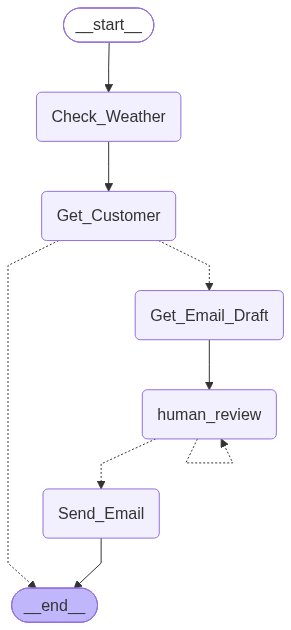

In [70]:
graph_builder = StateGraph(RunAState)
graph_builder.add_node("Check_Weather", weather_monitor_agent)
graph_builder.add_node("Get_Customer", targeting_customer_agent)
graph_builder.add_node("Get_Email_Draft", email_writing_agent)
graph_builder.add_node("human_review", human_review)
graph_builder.add_node("Send_Email", sender_agent)

graph_builder.add_edge(START, "Check_Weather")
graph_builder.add_edge("Check_Weather", "Get_Customer")
graph_builder.add_conditional_edges(
    "Get_Customer",
    route_after_targeting,
    {"Get_Email_Draft": "Get_Email_Draft", END: END},
)
graph_builder.add_edge("Get_Email_Draft", "human_review")
graph_builder.add_conditional_edges(
    "human_review",
    route_after_human_review,
    {"human_review": "human_review", "Send_Email": "Send_Email"},
)
graph_builder.add_edge("Send_Email", END)

graph = graph_builder.compile(checkpointer=checkpointer)

display(Image(graph.get_graph().draw_mermaid_png()))

## Try it end to end

In [ ]:
# Live OpenWeather data has no qualifying storm right now in any DB metro
# (Dallas, Austin, San Antonio, Denver, Colorado Springs, Tampa, Orlando,
# Miami, Jacksonville, Houston all checked clear/calm). To exercise the real
# DB lookup + real GPT draft generation end-to-end, simulate a qualifying
# StormEvent for one DB city and run it through the same node functions the
# graph uses (mirrors the manual test pattern used above for each node).

STORM_CITY = "Dallas"  # any DB metro works: Dallas, Austin, San Antonio, Denver,
                        # Colorado Springs, Tampa, Orlando, Miami, Jacksonville, Houston

simulated_event = StormEvent(
    city=STORM_CITY,
    condition_code=200,  # thunderstorm
    condition_text="thunderstorm with heavy rain",
    wind_speed=45,
    wind_units="mph",
    date=datetime.now(timezone.utc).date().isoformat(),
)
assert simulated_event.qualifies

monitor_result = {
    "storm_events": [simulated_event],
    "qualifying_cities": [STORM_CITY],
    "errors": [],
}

targeting_result = await targeting_customer_agent({"qualifying_cities": monitor_result["qualifying_cities"]})
personalizer_result = await email_writing_agent({
    "leads": targeting_result["leads"],
    "storm_events": monitor_result["storm_events"],
})

response = {**monitor_result, **targeting_result, **personalizer_result}

print("qualifying_cities:", response["qualifying_cities"])
print("leads:", len(response["leads"]))
print("drafts:", len(response["drafts"]))
if response["drafts"]:
    print(response["drafts"][0])


# try it: full graph run through the human review gate

Runs the compiled graph on one thread (`RUN_A_THREAD_ID`). Live OpenWeather data has
no active storm right now, so the demo seeds the graph's checkpoint with the simulated
drafts from the cell above -- as if `Get_Email_Draft` had just produced them -- via
`graph.aupdate_state(..., as_node="Get_Email_Draft")`, then resumes into `human_review`.

**The decisions below are SIMULATED, not a real review.** `human_review` genuinely
calls `interrupt()` and the graph genuinely pauses (checkpointed to Postgres) --
nothing auto-approves inside the graph itself. But the two "resume" cells that follow
feed it hardcoded decision dicts standing in for a human, purely to exercise the
interrupt -> resume -> rewrite-loop-back mechanics without a real UI. Swap those
hardcoded dicts for actual collected input (a CLI prompt, a frontend form, etc.)
before using this against real leads.

Walks through: first interrupt (all drafts pending) -> a simulated decision (approve
most, reject one, rewrite one) -> resume -> second interrupt (only the rewritten
draft comes back for another look, not the whole batch) -> simulated approve ->
resume -> `Send_Email` actually sends the approved emails via Gmail.

In [ ]:
RUN_A_THREAD_ID = str(uuid.uuid4())
config = {"configurable": {"thread_id": RUN_A_THREAD_ID}}

# Seed the checkpoint as if Get_Email_Draft had just produced these drafts, so
# the demo can reach human_review without waiting on a live storm.
await graph.aupdate_state(config, {"drafts": response["drafts"]}, as_node="Get_Email_Draft")

first_pass = await graph.ainvoke(None, config)
pending_payload = first_pass["__interrupt__"][0].value
print(f"human_review paused with {len(pending_payload['drafts'])} pending draft(s)")

In [ ]:
# SIMULATED human reviewer -- NOT real input. Hardcoded stand-in decisions so this
# cell can exercise the interrupt -> resume mechanics without a UI. Replace with
# actually-collected decisions (CLI prompt, frontend form, etc.) before real use.
pending_ids = [d["customer_id"] for d in pending_payload["drafts"]]

decisions_round_1 = {
    str(cid): {"action": "approve", "feedback": None, "edited_body": None}
    for cid in pending_ids
}
decisions_round_1[str(pending_ids[0])] = {
    "action": "reject",
    "feedback": "not a good fit right now",
    "edited_body": None,
}
decisions_round_1[str(pending_ids[1])] = {
    "action": "rewrite",
    "feedback": "make it shorter and mention we'll follow up by phone if they don't reply",
    "edited_body": None,
}
print("SIMULATED decisions (not real review input):", decisions_round_1)

second_pass = await graph.ainvoke(Command(resume=decisions_round_1), config)

In [ ]:
# If the rewrite came back, human_review paused again with just that one draft
# (route_after_human_review loops back only while a draft is still pending).
# The approval below is again SIMULATED -- not real review input.
if "__interrupt__" in second_pass:
    rewritten_payload = second_pass["__interrupt__"][0].value
    print(f"human_review paused again with {len(rewritten_payload['drafts'])} rewritten draft(s) to re-approve")
    for d in rewritten_payload["drafts"]:
        print(f"- customer {d['customer_id']}: {d['body'][:120]}...")

    decisions_round_2 = {
        str(d["customer_id"]): {"action": "approve", "feedback": None, "edited_body": None}
        for d in rewritten_payload["drafts"]
    }
    print("SIMULATED decisions (not real review input):", decisions_round_2)
    final_result = await graph.ainvoke(Command(resume=decisions_round_2), config)
else:
    final_result = second_pass

print("sent:", final_result.get("sent"))
if final_result.get("errors"):
    print("errors:", final_result["errors"])